# 12. Random numbers and random walk

How are random numbers generated by code? Practically we know it can be done using some Python built-in random number generator functions like the following,

In [1]:
import numpy as np
rlist = np.random.randint(0,2,100)
print(rlist)

[0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 0 1 1 1 0 1 0 0 0 0 1 0 0 1 0
 1 1 1 0 1 0 1 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 1 1 1 0 1 1 1 1 0 0 0 0 0 0 1
 1 0 1 0 1 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 0 0 0 1 1 1]


which generates random integers between in the interval [0,2) - but how is this achived on a computer? Isn't code supposed to mechanically crank out numbers following a predetermined recipe? How can we instill randomness in code? 

Before we answer these questions, I'd first like everyone to appreciate that it's not so easy to generate true randomness. We'll do a little competition between random numbers generated by you and by a machine. 

Below I have a little function that tests the nearest-neighbor correlation of a sequence of random zeros and ones. If your numbers are truely random, it would output a score of 0.25. (More explanations...)

In [2]:
def correlation(rlist):
    res = 0
    k=1
    for i in range(len(rlist)-k):
        res = res + rlist[i]*rlist[i+k]
    return res/(len(rlist)-1)

print(correlation( [0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1,0,0,1,1]) )

0.2631578947368421


0.26 is my current best shot. If we test this on random numbers generated by np.random.randint(), the average score is around 0.25.

In [3]:
len([0,0,1,0,1,1,0,1,0,1,0,0,1,1,1,0])

16

In [4]:
correlation([0,0,1,0,1,1,0,1,0,1,0,0,1,1,1,0,1,1,0,0])

0.21052631578947367

In [5]:
correlation([ 0, 0, 0, 1,  0, 1, 0, 0,   1 ,1 , 0,  0,  1, 0, 1,1])

0.13333333333333333

In [6]:
correlation([ 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0])

0.26666666666666666

In [6]:
for trial in range(10):
    print( correlation( np.random.randint(0,2,100)  ) )

0.2222222222222222
0.20202020202020202
0.24242424242424243
0.25252525252525254
0.23232323232323232
0.1111111111111111
0.2727272727272727
0.25252525252525254
0.20202020202020202
0.1919191919191919


If your zeros and ones are too close to each other like 0,0,0,0,1,1,1,1, it would output a socre close to 0.5. If your zeros and ones appear too orderly like 0,1,0,1,0,1, it would output 0. 

In [15]:
print(c( [0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,1] ))
print(c( [0,1,0,1,0,1,0,1,0,1])         )

0.5
0.0


Now it's your turn. Try your best to get close to 0.25!

## Pseudo random numbers
Through this little exercise we found that it's not to easy to generate truly random numbers. We have to fight the urge to alternate between 0 and 1 and at the same time the urge to repeat 0s and 1s. 

Coming back to our original question - then how do we generate randomness properly without any bias? The easiest way is to construct a long long list of carefully generated random numbers once and for all, and then choose a different starting point every time and read off numbers start from that point. There used to be real tomes of random numbers where you can flip to a page and start reading off a list of random numbers. 

Even if that is the case, how do we generate that long list in the first place?

The following code is a prototype, which generates **pseudorandom** numbers with a period of 9, within the range (0,9), both determined by M (which is 9 here). The key iterative process is r = (a*r +c) % M, where % means taking the remainder, or modulo.

In [9]:
def pseudo_rng(size = 10):
    a = 4
    c = 1
    M = 9
    r=3
    pseudo_list = []
    for i in range(size):
        r = (a*r + c)%M
        pseudo_list.append(r)
    return pseudo_list

print(pseudo_rng(20)) 

[4, 8, 6, 7, 2, 0, 1, 5, 3, 4, 8, 6, 7, 2, 0, 1, 5, 3, 4, 8]


If we want largers periods, we can always choose a larger M. For random numbers between (0,1), we can also rescale things.

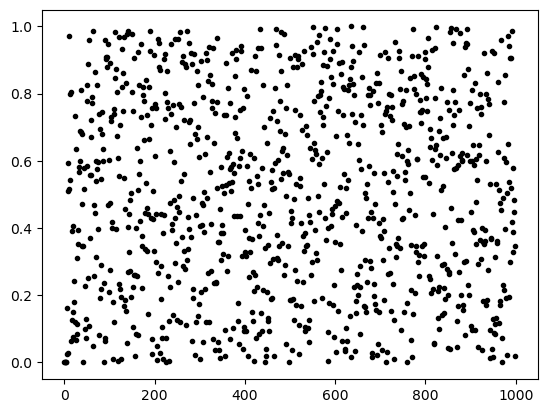

In [12]:
def pseudo_rng(size = 10):
    a = 123
    c = 11
    M = 2**48
    r= 2
    pseudo_list = []
    for i in range(size):
        r = (a*r + c)%M
        pseudo_list.append(r/M) #rescale between 0 and 1
    return pseudo_list

import matplotlib.pyplot as plt
p = plt.plot(pseudo_rng(1000), 'k.')

Notice that the pseudo random numbers are actually deterministically generated here, since the inital number r is the same every time we run this. 

This initial number that starts our sequence is called the **seed number**. To avoid a constant seed, we can assign an ever-changing number to it. e.g. we can assign the current time in microseconds as our seed.

In [2]:
from datetime import datetime
now = datetime.now()
now.microsecond # we can use this as our seed

427253

The following code will now generate a diffent sequence of random numbers every time it is run. Try it!

seed= 460237


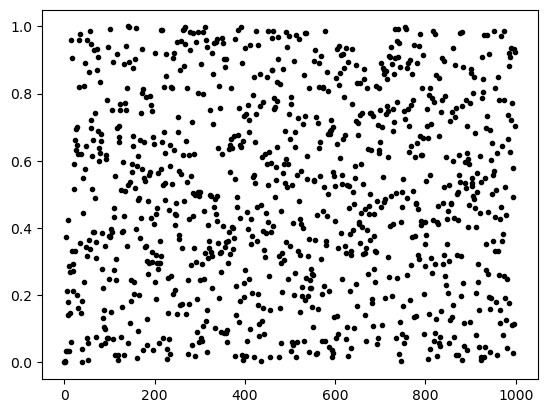

In [3]:
def pseudo_rng(size = 10):
    a = 123
    c = 11
    M = 2**48
    r = datetime.now().microsecond
    print('seed=',r)
    pseudo_list = []
    for i in range(size):
        r = (a*r + c)%M
        pseudo_list.append(r/M)
    return pseudo_list

import matplotlib.pyplot as plt
p = plt.plot(pseudo_rng(1000),'k.')

Are the numbers uniformly generated between 0 and 1? Let's demonstrate how to plot a histogram in matplotlib.

seed= 797400


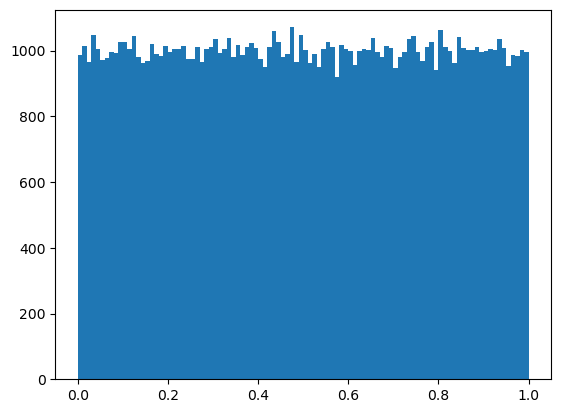

In [4]:
import matplotlib.pyplot as plt
phist = plt.hist(pseudo_rng(100000),bins=100)

# Simulating random processes 

In many physics processes we can simulate on a computer, we require random numbers. Examples include simulating determinisitc process like simply flipping coins or generating molecular motion at finite temperatures, where the random jiggling motion of atoms needs to be described or at least intialized by random numbers. Examples also include phyically probabalistic process like nuclear decay.  

## Numpy functions to generate random numbers
For starters, let's consider how random numbers can be generated by python. We'll introduce and test numpy functions first, and explain how random number generation is achieved in general in a later lecture.

There are often two ways of generating random numbers in numpy. The old way  is to use np.random.randint(), np.random.random(), and np.random.choice(). These were availble since numpy 1.1 and still are now. You may find these more often in online tutorials becasue they were there earlier.

The newer way since numpy 1.23 is to create a so-called generator object first using **np.random.default_rng()** and then use it to generate the random object of your choice.


For example, for random integers we can use randint to return us a numpy array.

In [ ]:
#your code here

Equivalently, for integers you can do 

In [ ]:
#your code here

For both methods, notice that if you run it multiple times, seeding is done automatically. To fix the seed, you can do the following. This is useful when you observe something special in a random experiment in python, and want to reproduce it.

In [ ]:
#your code here

So much for random integers. 

For random real numbers in an interval, there are also two methods:

If you just need the (0,1) interval, also two methods:

For random choice made from a list, again two methods.

In [8]:
#old
np.random.choice(['a','b'],10)

#newer, with generators;  more general and allows you to choose from a list of lists.
rng.choice([[0,0],[1,1],[2,2],[3,3]],    10) 

array([[2, 2],
       [2, 2],
       [0, 0],
       [2, 2],
       [0, 0],
       [1, 1],
       [2, 2],
       [0, 0],
       [3, 3],
       [1, 1]])

## Random walk, one particle

One the simplest prototypical physical model for random processes is the random walk model. We'll start with 1D.

In [1]:
#your code here

The average runtime was about 0.1 s for $10^4$ steps. 

The 1D random motion we generated looked erratic, but actually obeys statistical law. To see that, **our next goal is to perform statistical analysis to not just one but many particles doing random walk**. How many? Somewhere on the order of $10^4$ particles.

If we use our current random walk program, then you can estimate that it would take ~$0.1\times10^4$ = 1000 seconds to finish. So we will try to, again, **vectorize** our calculations in numpy. We'll find that replacing for loops in our program (that operates on single numbers one at a time) with numpy functions (that operate on entire arrays all at once) is almost always faster.

As a quick example, the following two functions both serve the same purpose: to generate N random integers.

In [14]:
#your code here

But the vectorized version (randomint2) is much faster

In [9]:
%time r=randomint1(1000000) #this takes about 2 seconds on my laptop

CPU times: user 1.74 s, sys: 16.8 ms, total: 1.76 s
Wall time: 1.76 s


In [10]:
%time r=randomint2(1000000) #but this only takes 0.03 seconds !

CPU times: user 25.5 ms, sys: 6.43 ms, total: 32 ms
Wall time: 29.8 ms


Going back to our 1D random walk code, we can do the following. Instead of generating random steps one at a time inside the for loop, we can generate all the random steps we need before entering the loop. Then inside the loop, when we need a random number at step i, simply access the i'th element of our random number list.

In [11]:
#your code here

The vectorized version will run ~100 times faster!

In [17]:
%time r=rw1(1e4)

CPU times: user 126 ms, sys: 14.6 ms, total: 141 ms
Wall time: 127 ms


In [18]:
%time r=rw2(1e4)

CPU times: user 7.26 ms, sys: 3.51 ms, total: 10.8 ms
Wall time: 12.1 ms


Seeing that there still a for loop remaining, you may want further improve upon that. We'll use the cumulative sum function to do that.

In [ ]:
#your code here

The end result looks something like this:

In [ ]:
#your code here

The only change is that we used a cumsum() to perform a cumulative sum on the array of -1s and +1s, so that it gives us the entire trajectory at every step.

At this point we have gained a huge speedup from version 1! We can now extend our code to handle more particles. 

## Random walk, $10^4$ particles, simple statistical analysis
As a first version for multi-particle random walk, we can contruct a for loop over all particles.

In [ ]:
#your code here

As before, whenever we see a for loop, we can ask ourselves if there is a way to operate directly on numpy arrays instead of element by element. In the multi-particle case, we can generate all the Nstep * Nparticle random steps that we need.

This can be done with either of the following 

rng.choice( [-1,1] , Nstep * Np).reshape([Np, Nstep])

rng.choice( [-1,1] , [Nstep, Np])

so that we end up with a 2D numpy array (or a matrix if you want to think about it that way) with dimensions Nstep * Nparticles.

When we do the cumsum() we'll choose axis = 1 to perform the cummulative sums along each row.

In [24]:
#your code here

CPU times: user 116 ms, sys: 18.1 ms, total: 134 ms
Wall time: 132 ms


In [ ]:
#your code here

Same result, but we're maximizing Python's efficiency.

As a last exercise, let's try to generate a distribution of all the particles at the very last step of the simulation. We do this using a slice along the last column.

In [ ]:
plt.figure()
plt.hist(rmulti[:,-1],bins=20,density=True)

Here we added an additional argument density=True so that the distribution is normalized, i.e. integrates to unity from -inf to +inf.

# Statistics, binomial distributions  


So far we've spent a lot of time honing our code and managed to vectorize our random walk model for best performance. We took advantage of generating all the random numbers we need at at once using rng.choice() and making quick cumulative sums using cumsum(). Below we're going to stick to the latested version of the multi-particle random walk code, rw_multi2().

The **main takeaway** of all the vectorizations we've done is not to memorize all these functions, but to keep in mind that, **whenever you're writing a for loop in python, explore numpy functions a bit more because there may be functions that achieves the same goal in a vectorized manner, which will almost always be faster than a for loop**. Again, the reason for this is that numpy functions like np.sum() or np.cumsum() are looping in a lower-level language (e.g. in C), and faster than looping in Python.

Now back to our model. Continuing from last time, let's plot the distributions of all the 10000 particle positions at different times in the simulations using histgrams. We'll slice through our final data (rmulti, a 2D Nparticle $\times$ Nstep numpy array) at the final timestep, at the middle of the simulation, and at a very early timestep. I chose the following slices: -1 (last), 500 (middle), and 50 (early).

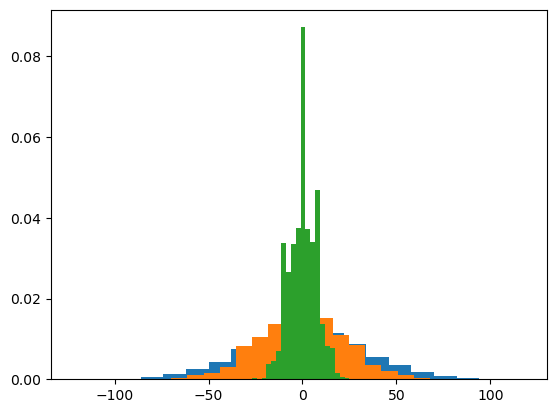

In [7]:
#your code here

Here we are still keeping the optional argument density=True, so that every distribution is normalized, i.e. integrates to unity from -inf to +inf.

Time evolves from green -> orange -> blue. We can see that all our particles start out at zero, and spreads out as everyone performs random walk. The spread increases with time, but how? Does the outward spread keep a constant speed? Accelerate? Decelerate? That we'll find out by inspecting the **standard deviation** of these distibutions. 

Let's calculate the mean positions and standard deviations of all the particles, at each step. We can use np.mean() along axis=0 to collect all the mean positions. Same with np.std() along axis=0. For each case we'll get an array of length Nstep, since the other dimension (Nparticles) as been processed.

In [2]:
#your code here

Now if we plot a selection of trajectories from 20 particles (just so that the plot doesn't get too crowded), along with the mean and standard deviation at every step in the same plot, we get the following.

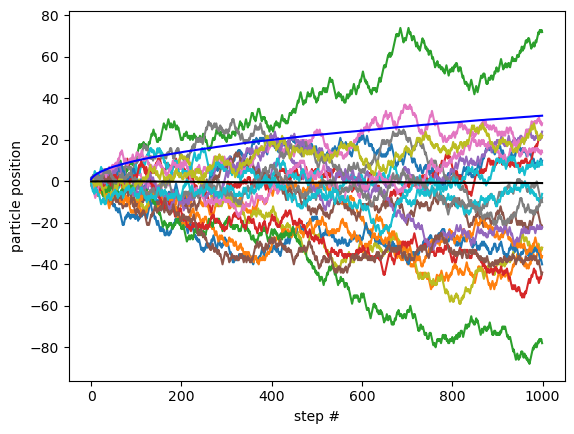

In [3]:
#your code here

Going from left to right, again we can see that are particles are spreading in the + and - directions. 

We also see the their mean position remains at zero. This is not surprising since, after all, everyone has the same probabability of stepping along + or -. This is also consistent with the three distributions we saw earlier all centered at 0.

Finally coming to the standard deviation = $\sqrt{ \text{average of (particle positions)}^2}$, we see that the spread actually increases sublinearly. If you make a $\sqrt{N}$ plot on top of this figure you'll see that **the spread of random walk particles follows $\sqrt{N}$ exactly**. 

This is a general result for random walk and diffusion in any dimesions. e.g. an ink drop in water diffuses and expands following a $\sqrt{\text{time}}$ behavior (with a prefactor called the diffusion coefficient).

But why $\sqrt{N}$?

## Binomial distribution

Random walk in 1D is similar to doing coin flips - 50% chance of getting heads (+1) and tails (–1) at every step. The distrbution of how many heads (or tails) you get in a coin flip experiment with $n$ flips is called the binomial distribtuion. You can expect that, for a fair coin, you're probably going to see somewhere around n/2 heads, but not exatly $n/2$ every time. For example, if you decide to flip 100 coins, one time you may end up seeing 48 heads, another time may 51. The final distribution of head counts will center around 50. 

In numpy, you can simulate this distribution using rng.binomial(n,p, N), where you can think of n as the total coin flips in every experiment (e.g. you can choose to toss $n=200$ coins in every experiment), $p$ is the probability of landing a head (e.g. $p=0.5$ for a fair coin), and N is the number of experiments (as many as you want).

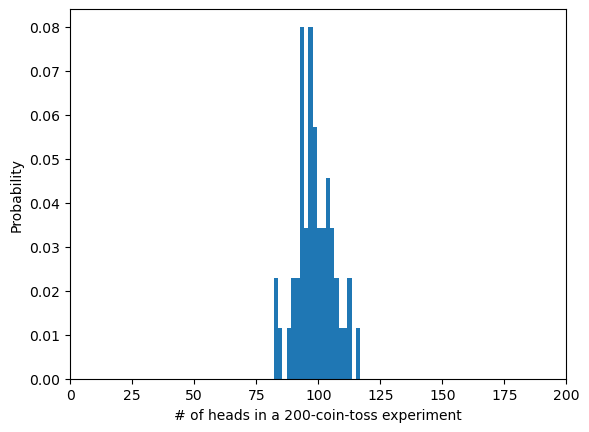

In [4]:
#your code here

As expected, in every experiment we toss 200 coins, we get somewhere between roughly 90 and 110 heads, roughly half of 200. If we want to make the distribution smoother we can conduct more 200-coin-toss experiments. Below I'll repeat it 100000 times.

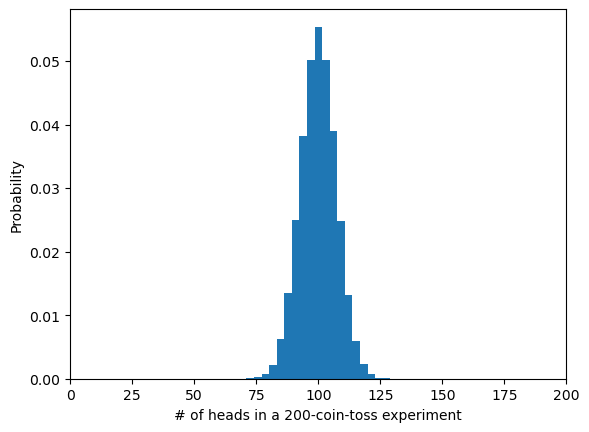

In [5]:
#your code here

We can related this result with random walk in the following way. Each time we get heads we move +1, and tails –1. Thus we can generate our random walk final positions by the following conversion: final position of random walk = (total number of heads) $\times$ (+1) + (total number of tails) $\times$ (–1). 

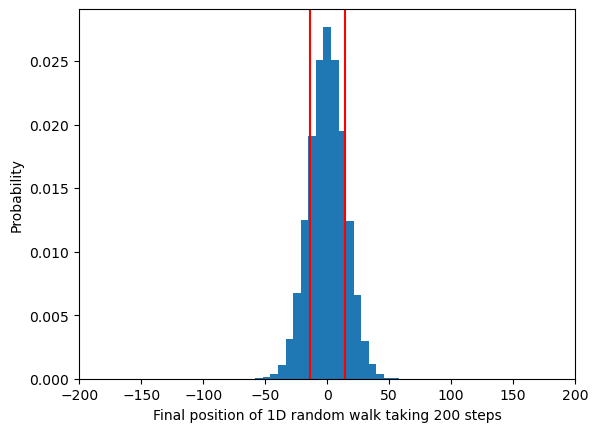

In [6]:
#your code here

And we get our binomial distribution of final positions with a spread of $\sqrt{n}$ as expected.

The standard deviation of the sample of binomial distribution is $\sqrt{n\times0.5\times0.5}$, a result from basic statistics that we're simply going to apply here. So the distribution of positions after applying random walk is $\sqrt{n\times0.5\times0.5}\times2 = \sqrt{n}$  

(Connections with the Central Limit Theorem, time permitting.)